In [2]:
library(lme4)
library(lmerTest)
library(emmeans)
library(sjPlot)
library(ordinal)
library(dplyr)

# Read #
df = read.csv('./SToP-COVID_mlm.csv')

NameError: name 'library' is not defined

In [ ]:
head(df)

,PID,Time_cat,Timepoint,Frequency,Solitariness,Avoid,Share,Worry,SCID,ifVax,...,COC,MES,OPI,KET,Due_to_psychoactive_substance_use,Schizophrenia_schizotypal_and_delusional_disorders,Mood_disorders,Disorders_of_adult_personality_and_behaviour,Neurotic_stress_related_and_somatoform_disorders,Onset_usually_occurring_in_childhood_and_adolescence
,<dbl>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2,T0,0,NA,5,NA,0,NA,NA,1,...,-0.5,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
2,2,T1,1,6,1,0,0,0,1,1,...,-0.5,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
3,2,T2,2,6,1,0,0,0,1,1,...,-0.5,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
4,2,T3,3,6,1,0,0,0,3,1,...,-0.5,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
5,3,T0,0,NA,1,NA,1,NA,NA,1,...,-0.5,-0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
6,3,T1,1,4,5,0,1,0,1,1,...,-0.5,-0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5


In [ ]:
### predictors ###
df$Time_cat = factor(df$Time_cat, levels=c('T1', 'T2', 'T3'))
T2_v_T1 = c(-1/3, 2/3, -1/3)
T3_v_T1 = c(-1/3, -1/3, 2/3)
contrasts(df$Time_cat) = cbind(T2_v_T1, T3_v_T1)
df$Worry_c = df$Worry - mean(df$Worry, na.rm=TRUE)
df$SCID_c  = df$SCID - mean(df$SCID, na.rm=TRUE)
df$ifVax_c = df$ifVax - 0.5
df$isInfected_c = df$isInfected - 0.5


# Baseline primary drug as a categorical, time-invariant covariate
# Methamphetamine is the reference category.
df$Primary = factor(
  df$Primary,
  levels = c('MET', 'THC', 'COC', 'MES', 'OPI', 'KET')
)
df$Primary = relevel(df$Primary, ref = 'MET')

### demos ###
df$Gender_c = df$Gender - 0.5
df$Age_c    = df$Age - mean(df$Age, na.rm=TRUE)

### post hocs ###

In [ ]:
model1_ordinal <- clmm(
  as.ordered(Frequency) ~ 1 + Time_cat +
    Primary +
    (1 | PID), 
  data = df[!is.na(df$Time_cat), ]
)
summary(model1_ordinal)
tab_model(model1_ordinal)

model2_ordinal <- clmm(
  as.ordered(Frequency) ~ 1 + Time_cat + Worry_c  + ifVax_c + isInfected_c +
    Due_to_psychoactive_substance_use+Mood_disorders+Neurotic_stress_related_and_somatoform_disorders+#Disorders_of_adult_personality_and_behaviour+Onset_usually_occurring_in_childhood_and_adolescence+
    (1 | PID), 
  data = df)
summary(model2_ordinal)
tab_model(model2_ordinal)

Cumulative Link Mixed Model fitted with the Laplace approximation

formula: as.ordered(Frequency) ~ 1 + Time_cat + MET + THC + COC + MES +  
    OPI + KET + (1 | PID)
data:    df[!is.na(df$Time_cat), ]

 link  threshold nobs logLik  AIC     niter      max.grad cond.H 
 logit flexible  312  -487.60 1003.19 1122(2337) 5.73e-04 2.5e+02

Random effects:
 Groups Name        Variance Std.Dev.
 PID    (Intercept) 0.4119   0.6418  
Number of groups:  PID 130 

Coefficients:
                 Estimate Std. Error z value Pr(>|z|)    
Time_catT2_v_T1 -1.139491   0.257117  -4.432 9.35e-06 ***
Time_catT3_v_T1 -1.506996   0.273256  -5.515 3.49e-08 ***
MET             -0.255214   0.316564  -0.806   0.4201    
THC              0.389219   0.324285   1.200   0.2300    
COC              0.577217   0.335238   1.722   0.0851 .  
MES              1.596017   0.386682   4.127 3.67e-05 ***
OPI              0.458421   0.426136   1.076   0.2820    
KET             -0.001063   0.468339  -0.002   0.9982    
---
Sig

Cumulative Link Mixed Model fitted with the Laplace approximation

formula: 
as.ordered(Frequency) ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c +  
    Due_to_psychoactive_substance_use + Mood_disorders + Neurotic_stress_related_and_somatoform_disorders +  
    (1 | PID)
data:    df

 link  threshold nobs logLik  AIC    niter      max.grad cond.H 
 logit flexible  302  -479.84 987.67 1206(3620) 7.88e-04 1.6e+02

Random effects:
 Groups Name        Variance Std.Dev.
 PID    (Intercept) 0.6742   0.8211  
Number of groups:  PID 125 

Coefficients:
                                                 Estimate Std. Error z value
Time_catT2_v_T1                                   -1.0928     0.2641  -4.137
Time_catT3_v_T1                                   -1.4691     0.2838  -5.176
Worry_c                                            0.1564     0.1700   0.919
ifVax_c                                            0.3103     0.4946   0.627
isInfected_c                                      -0.5750  

### MLM

In [ ]:
head(df, 2)

,PID,Time_cat,Timepoint,Frequency,Solitariness,Avoid,Share,Worry,SCID,ifVax,...,Mood_disorders,Disorders_of_adult_personality_and_behaviour,Neurotic_stress_related_and_somatoform_disorders,Onset_usually_occurring_in_childhood_and_adolescence,Worry_c,SCID_c,ifVax_c,isInfected_c,Gender_c,Age_c
,<dbl>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2,NA,0,NA,5,NA,0,NA,NA,1,...,-0.5,-0.5,-0.5,-0.5,NA,NA,0.5,-0.5,0.5,11.96923
2,2,T1,1,6,1,0,0,0,1,1,...,-0.5,-0.5,-0.5,-0.5,-0.5096154,-0.7147436,0.5,-0.5,0.5,11.96923


In [ ]:
model0_ordinal <- clmm(
  as.ordered(SCID) ~ 1 + Time_cat +
    (1 | PID), 
  data = df
)

# Model Summary
summary(model0_ordinal)
tab_model(model0_ordinal)

Cumulative Link Mixed Model fitted with the Laplace approximation

formula: as.ordered(SCID) ~ 1 + Time_cat + (1 | PID)
data:    df

 link  threshold nobs logLik  AIC    niter    max.grad cond.H 
 logit flexible  312  -415.75 843.51 309(929) 1.49e-04 1.6e+01

Random effects:
 Groups Name        Variance Std.Dev.
 PID    (Intercept) 0.6619   0.8136  
Number of groups:  PID 130 

Coefficients:
                Estimate Std. Error z value Pr(>|z|)    
Time_catT2_v_T1  -0.8720     0.2583  -3.376 0.000735 ***
Time_catT3_v_T1  -0.9355     0.2714  -3.447 0.000568 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Threshold coefficients:
    Estimate Std. Error z value
0|1  -1.6263     0.1924  -8.452
1|2  -0.2996     0.1487  -2.015
2|3   1.0152     0.1626   6.243
(208 observations deleted due to missingness)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: SCID ~ 1 + Time_cat + (1 | PID)
   Data: df

REML criterion at convergence: 928.6

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-2.07401 -0.69916 -0.01113  0.82189  1.70207 

Random effects:
 Groups   Name        Variance Std.Dev.
 PID      (Intercept) 0.2215   0.4706  
 Residual             0.9400   0.9695  
Number of obs: 312, groups:  PID, 130

Fixed effects:
                Estimate Std. Error       df t value Pr(>|t|)    
(Intercept)       1.6778     0.0705 128.7208  23.798  < 2e-16 ***
Time_catT2_v_T1  -0.4899     0.1313 207.9872  -3.732 0.000245 ***
Time_catT3_v_T1  -0.5229     0.1382 215.9832  -3.784 0.000200 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Correlation of Fixed Effects:
            (Intr) T_T2__
Tm_ctT2__T1 0.105        
Tm_ctT3__T1 0.164  0.407 

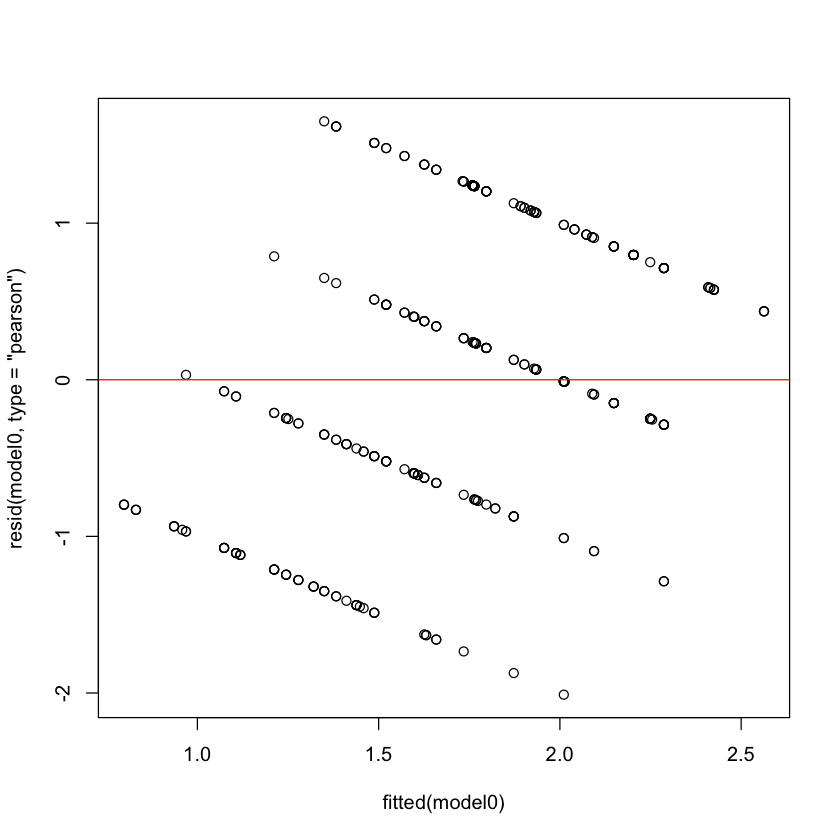

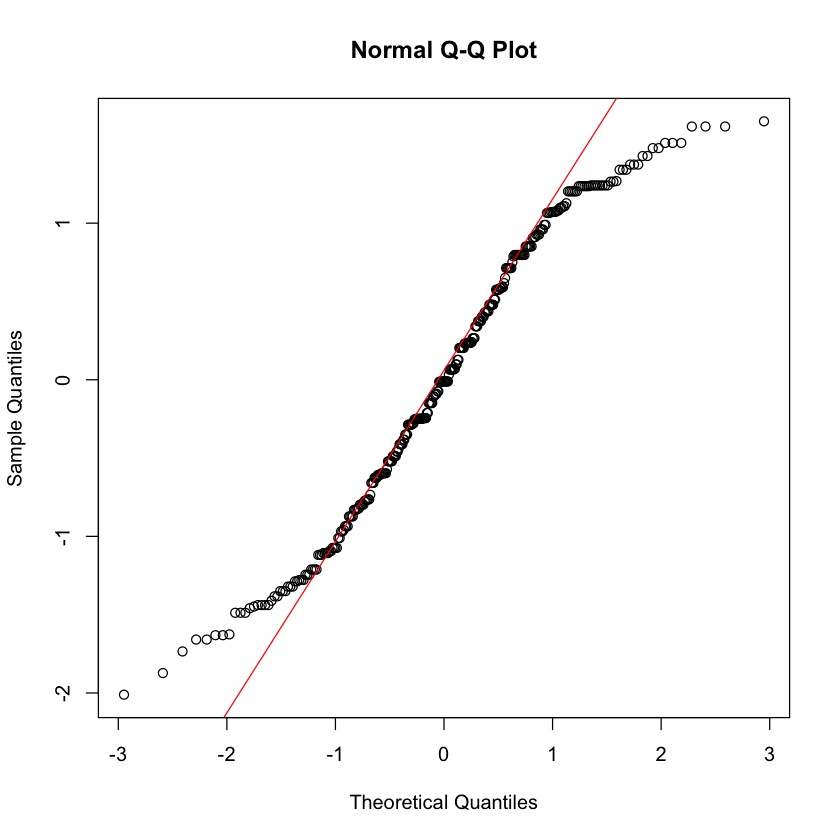

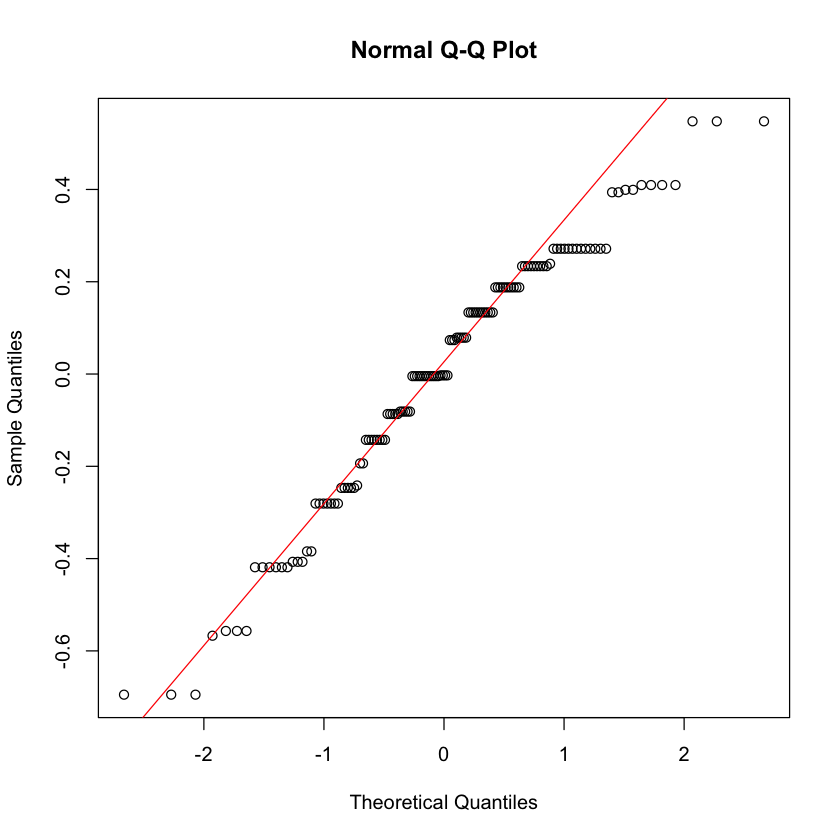

In [ ]:
### lmer ###
measure = 'SCID'
model0 = lmer(SCID ~ 1 + Time_cat + 
              (1 | PID), data = df)

# model0 Result #
summary(model0)
tab_model(model0, digits = 2, file = paste('./mlm_', measure, '.html', sep = '')) # .doc

# DIAGNOSTICS #
plot(fitted(model0), resid(model0, type = "pearson")); abline(0, 0, col="red") ## Check for homoscedasticity
qqnorm(resid(model0)); qqline(resid(model0), col = "red") ## QQ-plot to check normality of residuals
qqnorm(ranef(model0)$PID[ , 1] ); qqline(ranef(model0)$PID[ , 1], col = "red") ## Check normality random intercept
tab_model(model0)


In [ ]:
model0_ordinal <- clmm(
  as.ordered(SCID) ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c +
    (1 | PID), 
  data = df
)

# Model Summary
summary(model0_ordinal)

Cumulative Link Mixed Model fitted with the Laplace approximation

formula: as.ordered(SCID) ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c +  
    (1 | PID)
data:    df

 link  threshold nobs logLik  AIC    niter     max.grad cond.H 
 logit flexible  302  -399.97 817.94 581(1745) 9.95e-05 6.9e+01

Random effects:
 Groups Name        Variance Std.Dev.
 PID    (Intercept) 0.7466   0.864   
Number of groups:  PID 125 

Coefficients:
                Estimate Std. Error z value Pr(>|z|)    
Time_catT2_v_T1 -0.86025    0.26621  -3.231 0.001232 ** 
Time_catT3_v_T1 -0.95814    0.28225  -3.395 0.000687 ***
Worry_c          0.05387    0.16878   0.319 0.749575    
ifVax_c         -0.82198    0.54753  -1.501 0.133289    
isInfected_c    -0.01547    0.30422  -0.051 0.959437    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Threshold coefficients:
    Estimate Std. Error z value
0|1  -2.0144     0.3273  -6.154
1|2  -0.6560     0.2921  -2.246
2|3   0.6624     0.2881   2.299


Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: 
Frequency ~ 1 + Time_cat + Worry_c + SCID_c + ifVax_c + isInfected_c +  
    (1 | PID)
   Data: df

REML criterion at convergence: 1103.2

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-2.3141 -0.7943  0.0533  0.7419  2.4207 

Random effects:
 Groups   Name        Variance Std.Dev.
 PID      (Intercept) 0.2376   0.4875  
 Residual             1.9971   1.4132  
Number of obs: 302, groups:  PID, 125

Fixed effects:
                 Estimate Std. Error        df t value Pr(>|t|)    
(Intercept)       3.58903    0.18460 160.09895  19.443  < 2e-16 ***
Time_catT2_v_T1  -0.71384    0.19920 205.35560  -3.584 0.000423 ***
Time_catT3_v_T1  -1.02308    0.21125 219.88151  -4.843 2.41e-06 ***
Worry_c           0.11337    0.12110 233.36721   0.936 0.350140    
SCID_c            0.56616    0.08108 289.35008   6.983 1.99e-11 ***
ifVax_c           0.41892    0.36106 165.25026   1.160 0.247614  

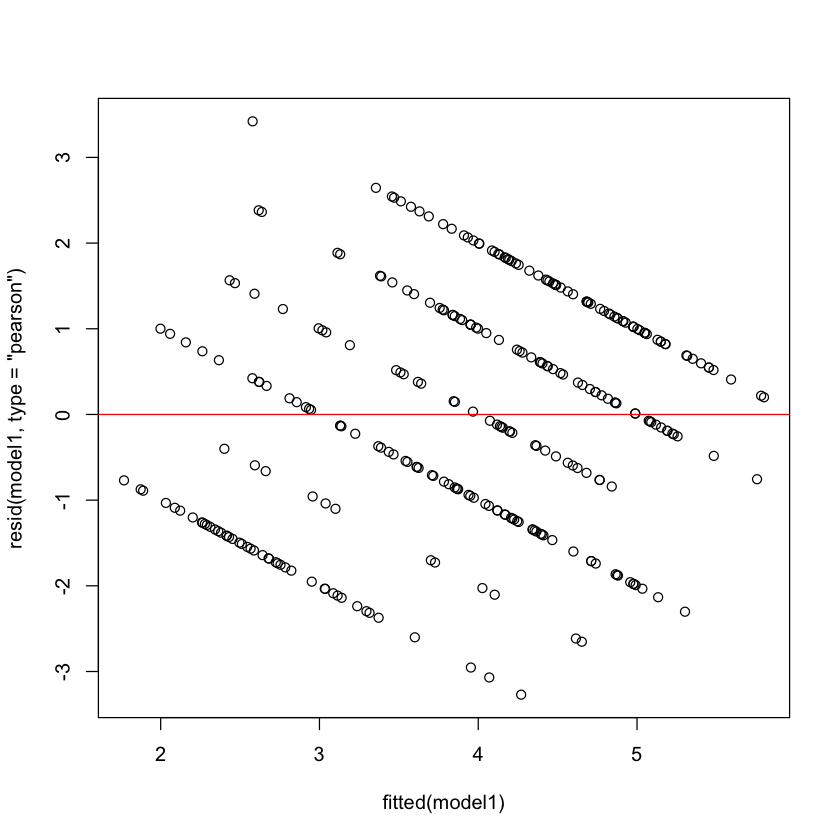

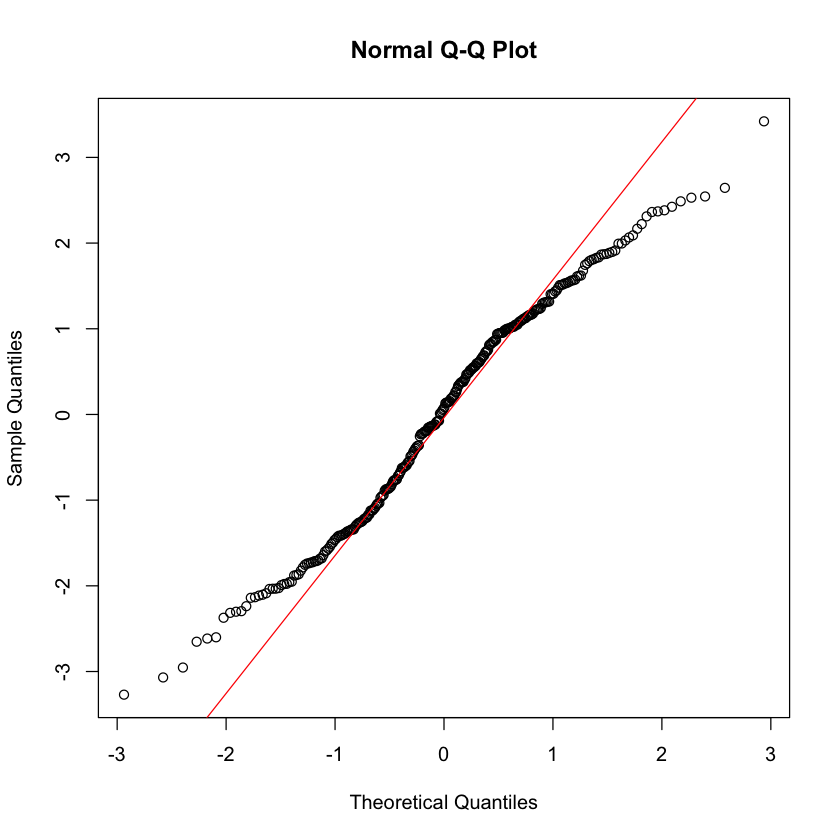

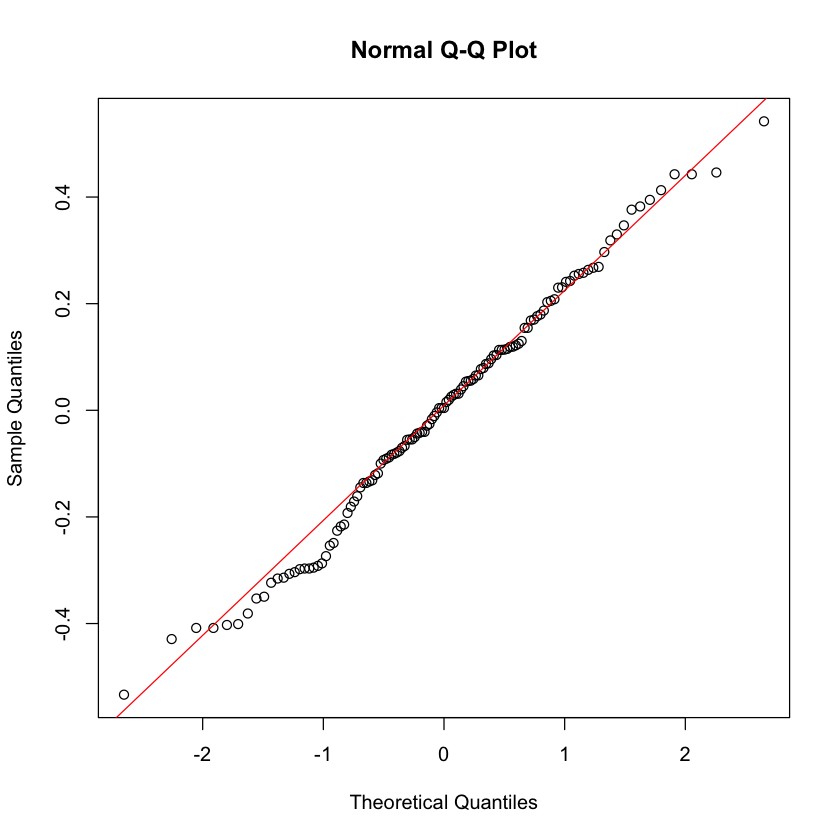

In [ ]:
### lmer ###
measure = 'Frequency'
model1 = lmer(Frequency ~ 1 + Time_cat + Worry_c + SCID_c + ifVax_c + isInfected_c + 
              (1 | PID), data = df)

# model1 Result #
summary(model1)
tab_model(model1, digits = 2, file = paste('./mlm_', measure, '.html', sep = '')) # .doc

# DIAGNOSTICS #
plot(fitted(model1), resid(model1, type = "pearson")); abline(0, 0, col="red") ## Check for homoscedasticity
qqnorm(resid(model1)); qqline(resid(model1), col = "red") ## QQ-plot to check normality of residuals
qqnorm(ranef(model1)$PID[ , 1] ); qqline(ranef(model1)$PID[ , 1], col = "red") ## Check normality random intercept

In [ ]:
model1_ordinal <- clmm(
  as.ordered(Frequency) ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c +
    (1 | PID), 
  data = df
)

# Model Summary
summary(model1_ordinal)

Cumulative Link Mixed Model fitted with the Laplace approximation

formula: 
as.ordered(Frequency) ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c +  
    (1 | PID)
data:    df

 link  threshold nobs logLik  AIC    niter     max.grad cond.H 
 logit flexible  302  -482.93 987.85 901(2705) 7.76e-04 1.4e+02

Random effects:
 Groups Name        Variance Std.Dev.
 PID    (Intercept) 0.7882   0.8878  
Number of groups:  PID 125 

Coefficients:
                Estimate Std. Error z value Pr(>|z|)    
Time_catT2_v_T1  -1.0783     0.2648  -4.073 4.64e-05 ***
Time_catT3_v_T1  -1.4679     0.2841  -5.167 2.38e-07 ***
Worry_c           0.2061     0.1713   1.203   0.2289    
ifVax_c           0.3407     0.5056   0.674   0.5005    
isInfected_c     -0.6294     0.3040  -2.070   0.0384 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Threshold coefficients:
    Estimate Std. Error z value
1|2 -1.73402    0.29986  -5.783
2|3 -1.39598    0.28857  -4.838
3|4  0.02602    0.26911   

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: Solitariness ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c +  
    (1 | PID)
   Data: df

REML criterion at convergence: 941.2

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-2.1168 -0.5967 -0.1636  0.6302  2.0436 

Random effects:
 Groups   Name        Variance Std.Dev.
 PID      (Intercept) 1.192    1.092   
 Residual             1.435    1.198   
Number of obs: 256, groups:  PID, 125

Fixed effects:
                  Estimate Std. Error         df t value Pr(>|t|)    
(Intercept)       2.700878   0.232593 141.568229  11.612   <2e-16 ***
Time_catT2_v_T1  -0.084508   0.186693 156.918739  -0.453    0.651    
Time_catT3_v_T1  -0.298698   0.205595 161.990506  -1.453    0.148    
Worry_c          -0.003371   0.136429 246.472107  -0.025    0.980    
ifVax_c           0.313238   0.446266 140.003664   0.702    0.484    
isInfected_c      0.398258   0.283002 121.590139   1.407    0

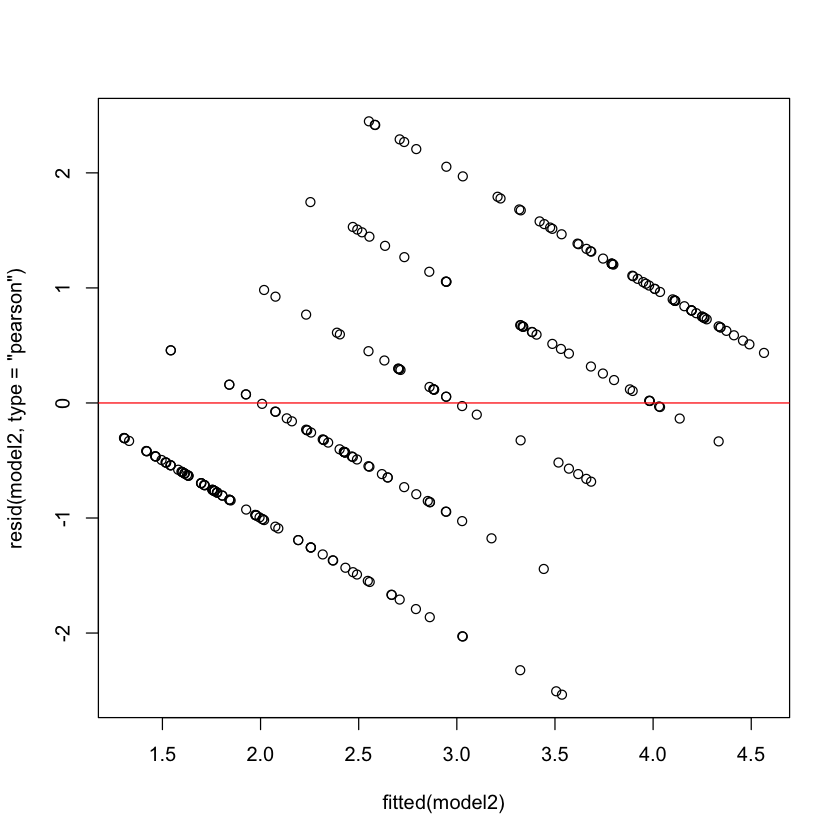

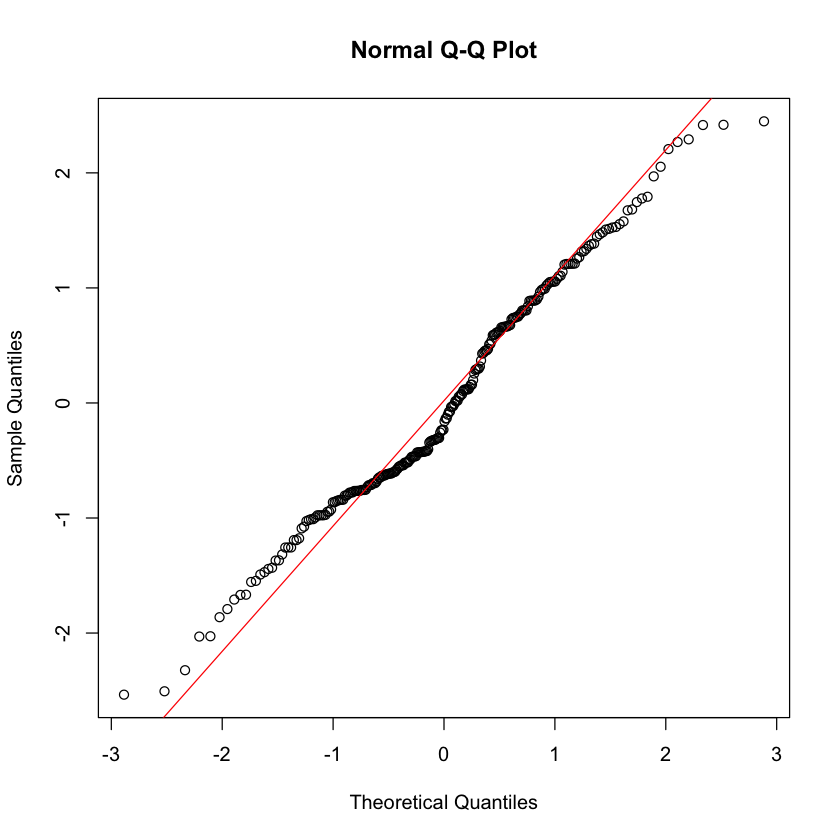

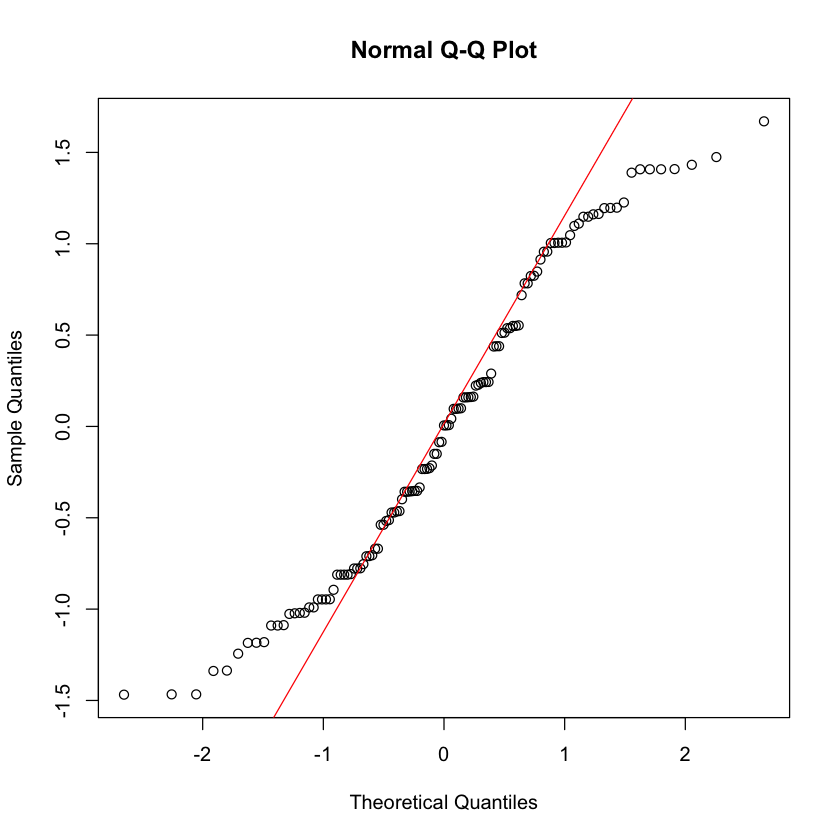

In [ ]:
### lmer ###
measure = 'Solitariness'
model2 = lmer(Solitariness ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c + 
              (1 | PID), data = df)

# model2 Result #
summary(model2)
tab_model(model2, digits = 2, file = paste('./mlm_', measure, '.html', sep = '')) # .doc

# DIAGNOSTICS #
plot(fitted(model2), resid(model2, type = "pearson")); abline(0, 0, col="red") ## Check for homoscedasticity
qqnorm(resid(model2)); qqline(resid(model2), col = "red") ## QQ-plot to check normality of residuals
qqnorm(ranef(model2)$PID[ , 1] ); qqline(ranef(model2)$PID[ , 1], col = "red") ## Check normality random intercept

In [ ]:
model2_ordinal <- clmm(
  as.ordered(Solitariness) ~ Time_cat + Worry_c + ifVax_c + isInfected_c +
    (1 | PID), 
  data = df
)

# Model Summary
summary(model2_ordinal)

Cumulative Link Mixed Model fitted with the Laplace approximation

formula: 
as.ordered(Solitariness) ~ Time_cat + Worry_c + ifVax_c + isInfected_c +  
    (1 | PID)
data:    df

 link  threshold nobs logLik  AIC    niter     max.grad cond.H 
 logit flexible  256  -372.98 765.96 630(2455) 1.11e-04 1.7e+02

Random effects:
 Groups Name        Variance Std.Dev.
 PID    (Intercept) 2.434    1.56    
Number of groups:  PID 125 

Coefficients:
                 Estimate Std. Error z value Pr(>|z|)
Time_catT2_v_T1 -0.131542   0.310085  -0.424    0.671
Time_catT3_v_T1 -0.520162   0.347744  -1.496    0.135
Worry_c         -0.001301   0.217960  -0.006    0.995
ifVax_c          0.683254   0.687017   0.995    0.320
isInfected_c     0.522282   0.437421   1.194    0.232

Threshold coefficients:
    Estimate Std. Error z value
1|2  -0.7769     0.3758  -2.067
2|3   0.3113     0.3708   0.839
3|4   0.9403     0.3787   2.483
4|5   1.8536     0.4053   4.574
(264 observations deleted due to missingness)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: binomial  ( logit )
Formula: Avoid ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c + (1 |  
    PID)
   Data: df

     AIC      BIC   logLik deviance df.resid 
   286.6    311.4   -136.3    272.6      249 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.7171 -0.5066 -0.4008  0.7063  2.5579 

Random effects:
 Groups Name        Variance Std.Dev.
 PID    (Intercept) 0.3867   0.6219  
Number of obs: 256, groups:  PID, 125

Fixed effects:
                Estimate Std. Error z value Pr(>|z|)    
(Intercept)      -1.1668     0.3390  -3.442 0.000577 ***
Time_catT2_v_T1  -0.7077     0.3836  -1.845 0.065079 .  
Time_catT3_v_T1  -0.6002     0.4206  -1.427 0.153560    
Worry_c           0.8904     0.2241   3.974 7.07e-05 ***
ifVax_c          -0.3561     0.5889  -0.605 0.545343    
isInfected_c     -0.1230     0.3726  -0.330 0.741358    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.

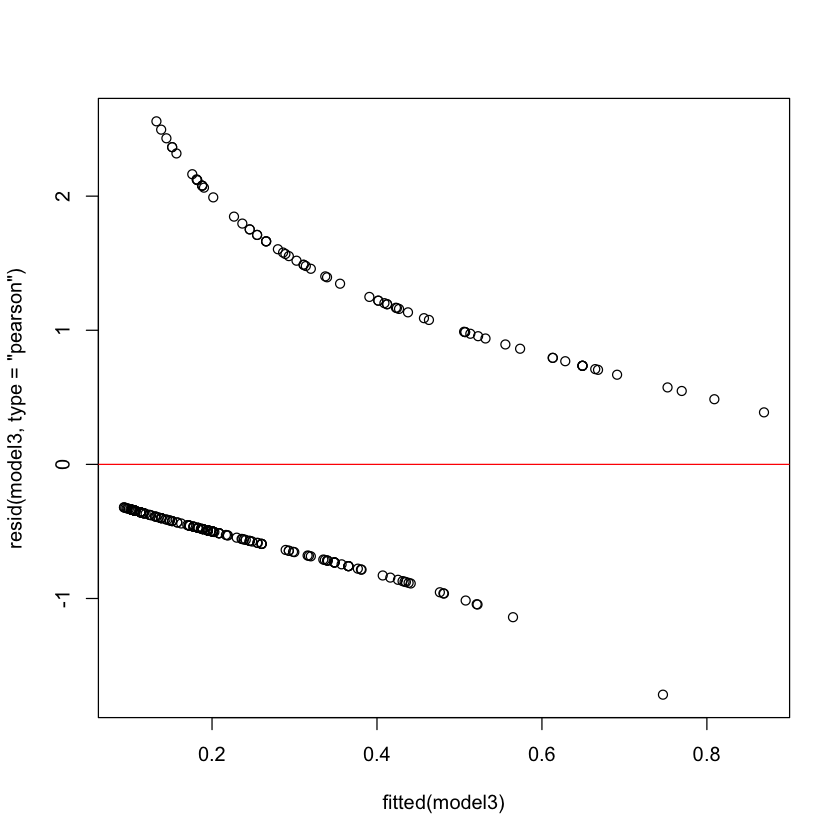

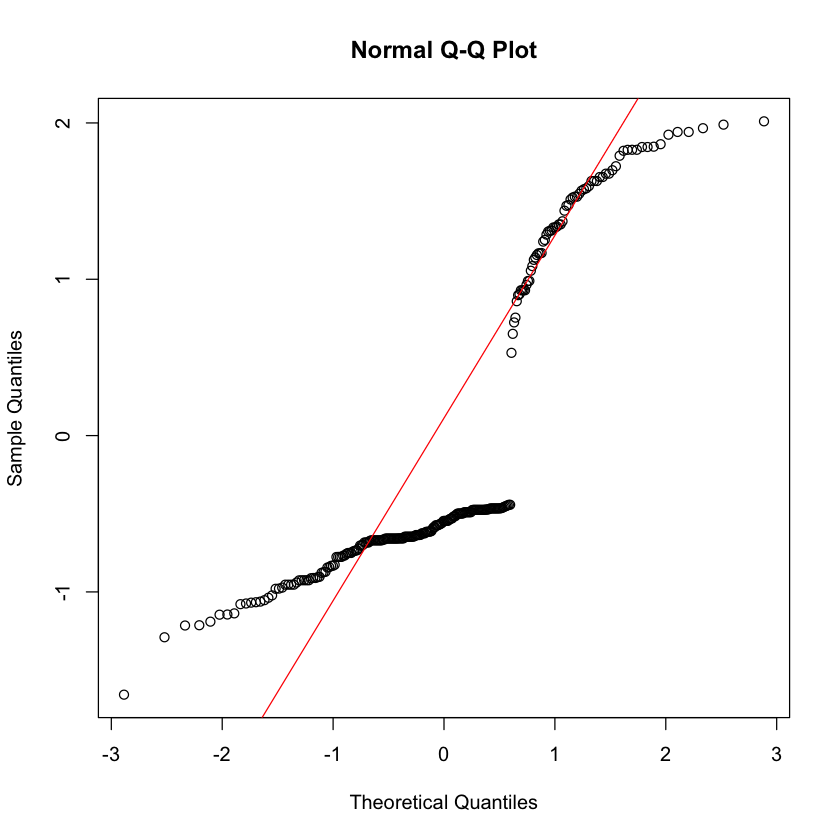

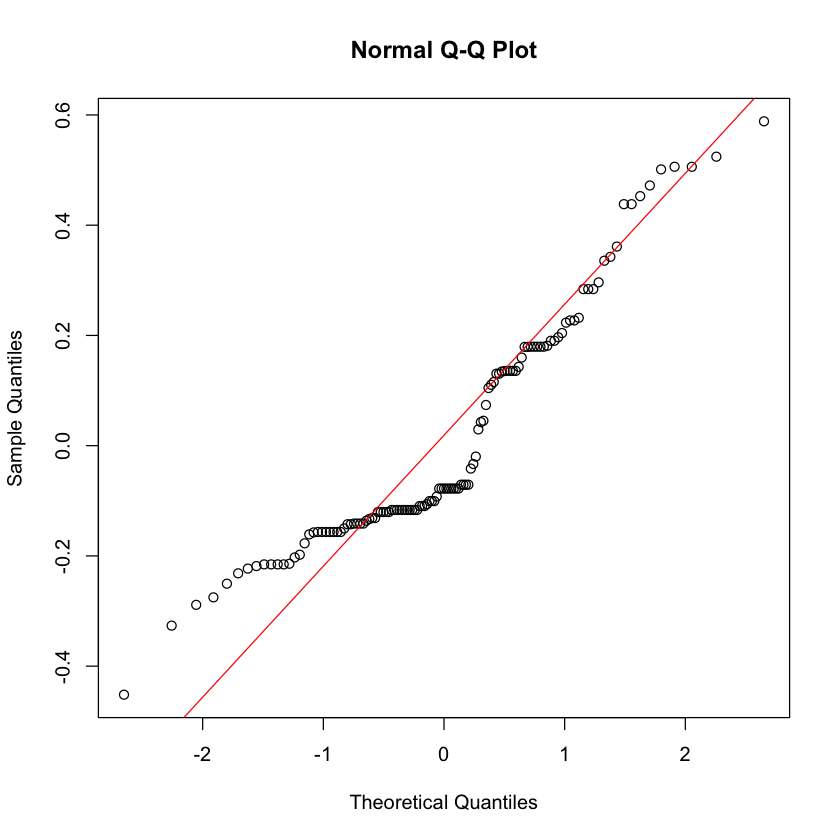

In [ ]:
### lmer ###
measure = 'Avoid'
model3 = glmer(Avoid ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c + 
              (1 | PID), family='binomial', data = df)

# model3 Result #
summary(model3)
tab_model(model3, digits = 2, file = paste('./mlm_', measure, '.html', sep = '')) # .doc

# # DIAGNOSTICS #
plot(fitted(model3), resid(model3, type = "pearson")); abline(0, 0, col="red") ## Check for homoscedasticity
qqnorm(resid(model3)); qqline(resid(model3), col = "red") ## QQ-plot to check normality of residuals
qqnorm(ranef(model3)$PID[ , 1] ); qqline(ranef(model3)$PID[ , 1], col = "red") ## Check normality random intercept

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: binomial  ( logit )
Formula: Share ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c + (1 |  
    PID)
   Data: df

     AIC      BIC   logLik deviance df.resid 
   336.6    361.5   -161.3    322.6      249 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.8000 -0.5833  0.2821  0.5695  1.8632 

Random effects:
 Groups Name        Variance Std.Dev.
 PID    (Intercept) 2.91     1.706   
Number of obs: 256, groups:  PID, 125

Fixed effects:
                Estimate Std. Error z value Pr(>|z|)   
(Intercept)      -0.5342     0.4498  -1.188  0.23498   
Time_catT2_v_T1  -0.4803     0.4022  -1.194  0.23231   
Time_catT3_v_T1  -1.4407     0.4782  -3.013  0.00259 **
Worry_c          -0.5931     0.2836  -2.092  0.03648 * 
ifVax_c           1.3139     0.8711   1.508  0.13148   
isInfected_c      0.5631     0.5263   1.070  0.28469   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 

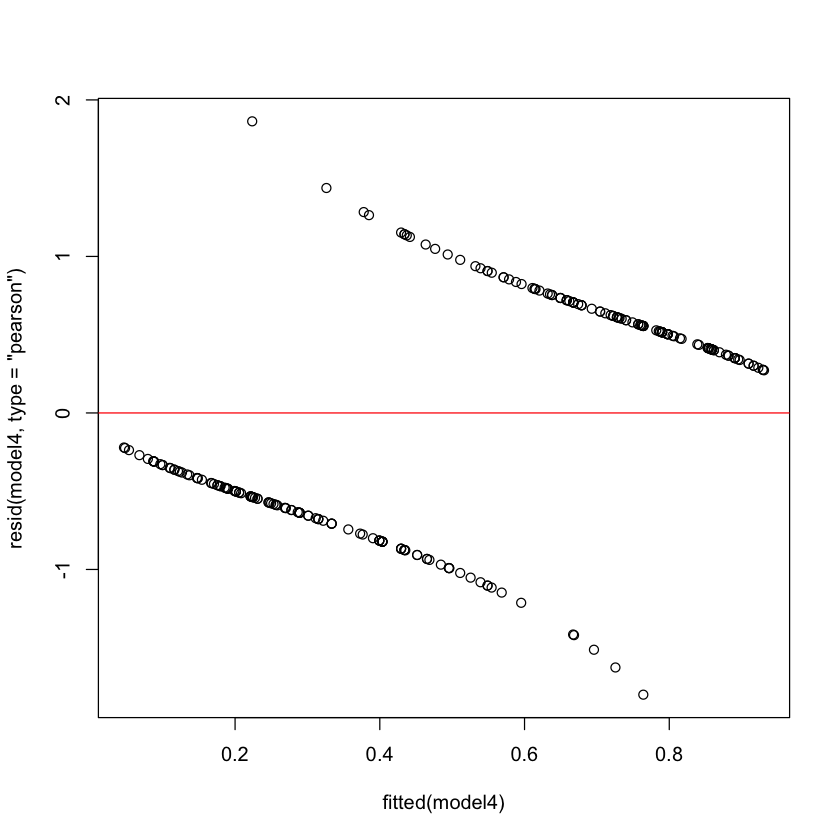

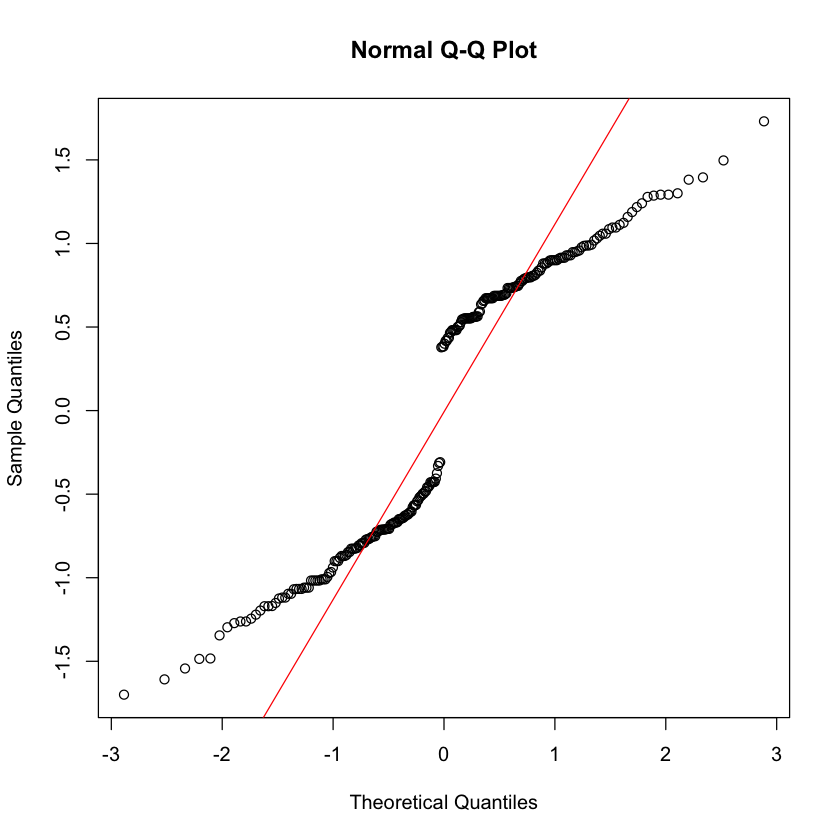

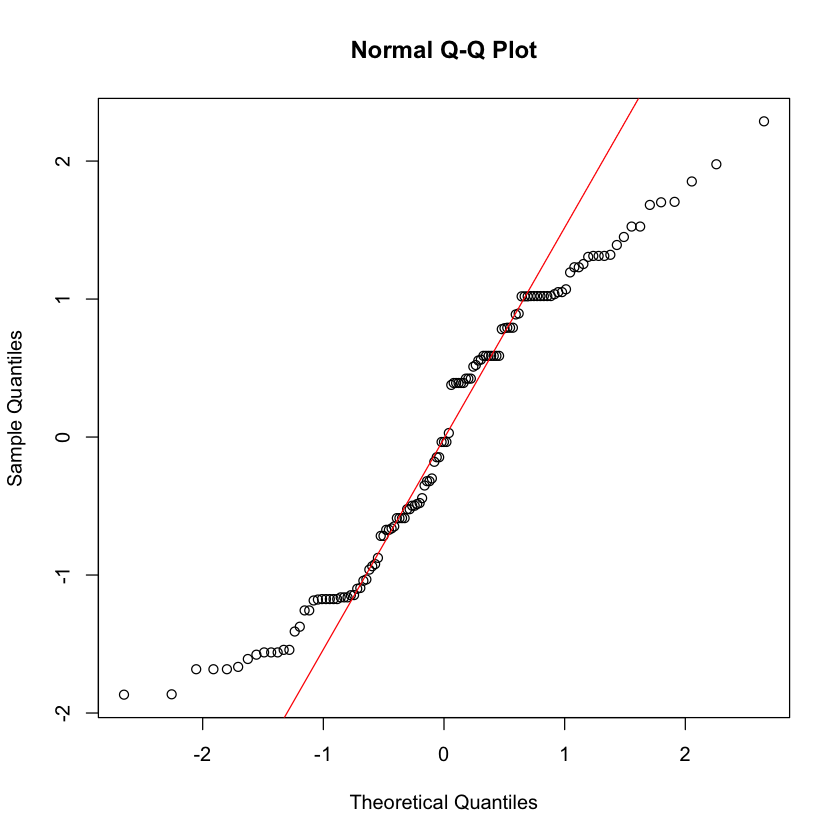

In [ ]:
### lmer ###
measure = 'Share'
model4 = glmer(Share ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c + 
              (1 | PID), family='binomial', data = df)

# model4 Result #
summary(model4)
tab_model(model4, digits = 2, file = paste('./mlm_', measure, '.html', sep = '')) # .doc

# # DIAGNOSTICS #
plot(fitted(model4), resid(model4, type = "pearson")); abline(0, 0, col="red") ## Check for homoscedasticity
qqnorm(resid(model4)); qqline(resid(model4), col = "red") ## QQ-plot to check normality of residuals
qqnorm(ranef(model4)$PID[ , 1] ); qqline(ranef(model4)$PID[ , 1], col = "red") ## Check normality random intercepta

In [ ]:
tab_model(model0_ordinal, model1_ordinal, model3, model4, model2_ordinal, digits = 2, file = './mlm_all.doc')

### Post-hoc1: Drug subtypes

In [ ]:
# Model 0
model0_ordinal <- clmm(
  as.ordered(SCID) ~ 1 + Time_cat + Worry_c  + ifVax_c + isInfected_c +
    Primary +
    (1 | PID), 
  data = df
)
# summary(model1_ordinal)

# Model 1
model1_ordinal <- clmm(
  as.ordered(Frequency) ~ 1 + Time_cat + Worry_c + ifVax_c + isInfected_c +
    Primary +
    (1 | PID), 
  data = df
)
# summary(model1_ordinal)


# Model 2
model2_ordinal <- clmm(
  as.ordered(Solitariness) ~ Time_cat + Worry_c  + ifVax_c + isInfected_c +
    Primary +
    (1 | PID), 
  data = df
)
# summary(model2_ordinal)

# Model 3
model3 = glmer(Avoid ~ 1 + Time_cat + Worry_c  + ifVax_c + isInfected_c + 
               Primary +
              (1 | PID), family='binomial', data = df)

# Model 4
model4 = glmer(Share ~ 1 + Time_cat + Worry_c  + ifVax_c + isInfected_c + 
               Primary +
              (1 | PID), family='binomial', data = df)

tab_model(model0_ordinal, model1_ordinal, model3, model4, model2_ordinal, digits = 2, file = './mlm_posthoc_drug.doc')

Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model failed to converge with max|grad| = 0.0141325 (tol = 0.002, component 1)”
Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model failed to converge with max|grad| = 0.00886981 (tol = 0.002, component 1)”


### Post-hoc2: Comorbid psychiatric conditions

In [ ]:
# Model 0
model0_ordinal <- clmm(
  as.ordered(SCID) ~ 1 + Time_cat + Worry_c  + ifVax_c + isInfected_c +
    Due_to_psychoactive_substance_use+Mood_disorders+Neurotic_stress_related_and_somatoform_disorders+#Disorders_of_adult_personality_and_behaviour+Onset_usually_occurring_in_childhood_and_adolescence+
    (1 | PID), 
  data = df
)
# summary(model0_ordinal)

# Model 1
model1_ordinal <- clmm(
  as.ordered(Frequency) ~ 1 + Time_cat + Worry_c  + ifVax_c + isInfected_c +
#     Due_to_psychoactive_substance_use+Mood_disorders+Neurotic_stress_related_and_somatoform_disorders+#Disorders_of_adult_personality_and_behaviour+Onset_usually_occurring_in_childhood_and_adolescence+
    (1 | PID), 
  data = df
)
# summary(model1_ordinal)

# Model 2
model2_ordinal <- clmm(
  as.ordered(Solitariness) ~ Time_cat + Worry_c  + ifVax_c + isInfected_c +
    Due_to_psychoactive_substance_use+Mood_disorders+Neurotic_stress_related_and_somatoform_disorders+#Disorders_of_adult_personality_and_behaviour+Onset_usually_occurring_in_childhood_and_adolescence+
    (1 | PID), 
  data = df
)
# summary(model2_ordinal)

# Model 3
model3 = glmer(Avoid ~ 1 + Time_cat + Worry_c  + ifVax_c + isInfected_c + 
              Due_to_psychoactive_substance_use+Mood_disorders+Neurotic_stress_related_and_somatoform_disorders+#Disorders_of_adult_personality_and_behaviour+Onset_usually_occurring_in_childhood_and_adolescence+
              (1 | PID), family='binomial', data = df)

# Model 4
model4 = glmer(Share ~ 1 + Time_cat + Worry_c  + ifVax_c + isInfected_c + 
              Due_to_psychoactive_substance_use+Mood_disorders+Neurotic_stress_related_and_somatoform_disorders+#Disorders_of_adult_personality_and_behaviour+Onset_usually_occurring_in_childhood_and_adolescence+
              (1 | PID), family='binomial', data = df)

tab_model(model0_ordinal, model1_ordinal, model3, model4, model2_ordinal, digits = 2, file = './mlm_posthoc_comorbid.doc')

Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model failed to converge with max|grad| = 0.0538342 (tol = 0.002, component 1)”
Warning message in checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv, :
“Model failed to converge with max|grad| = 0.0360355 (tol = 0.002, component 1)”


In [ ]:
# model1_linear <- lmer(
#   Frequency ~ Time_cat + Worry_c  + ifVax_c + isInfected_c +
#     MET + THC + COC + MES + OPI + KET +
#     (1 | PID), 
#   data = df[!is.na(df$Time_cat), ],
# )
# summary(model1_linear)

# model2_linear <- lmer(
#   Frequency ~ Time_cat + Worry_c  + ifVax_c + isInfected_c +
#     Due_to_psychoactive_substance_use+Mood_disorders+Neurotic_stress_related_and_somatoform_disorders+
#     (1 | PID), 
#   data = df[!is.na(df$Time_cat), ],
# )
# summary(model2_linear)